<div style="background-color: #1E3A8A; color: white; padding: 20px; border-radius: 10px; text-align: center;">
  <h1 style="margin: 0; color: #FDBB30;">Module 4: Clinical Prompt Engineering in CLIP</h1>
  <h3 style="margin-top: 8px; font-weight: normal; color: #E2E8F0;">Teaching Vision-Language Models to "See" Like a Pathologist</h3>
  <p style="margin: 0; font-size: 14px;"><b>Kennesaw State University | iCARE Lab | Sophomore Scholars (2026–2027)</b></p>
</div>

<br>

<div style="background-color: #FEF2F2; border-left: 6px solid #DC2626; padding: 15px; border-radius: 6px;">
  <h3 style="color: #991B1B; margin-top: 0;">🔴 The Puzzle from Year 1: Why Did CLIP Fail on Microscope Slides?</h3>
  <p style="color: #7F1D1D; font-size: 15px; margin-bottom: 0;">
    In Year 1, we tested OpenAI's <b>CLIP</b> model on breast cancer microscope slides (Zero-Shot, with zero training).
    When we gave CLIP the simple text prompt <b><code>"a histopathology image of cancerous tissue"</code></b>, it scored an <b>AUC-ROC of only 0.413</b> (worse than flipping a coin!).
    <br><br>
    <b>Why?</b> Because standard CLIP learned from everyday internet photos (dogs, cars, beaches). It does not know what the medical word <i>"cancerous"</i> looks like under a microscope!
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Today's Big Idea: Describe the Colors and Shapes!</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    Even if a person has never gone to medical school, you can teach them to spot breast cancer on a slide by describing what it <b>looks like visually</b>:
    <ul>
      <li style="color: #14532D;"><b>Healthy (Benign) Slide:</b> Light pink background with neat, evenly spaced, calm cells.</li>
      <li style="color: #14532D;"><b>Cancerous (Malignant) Slide:</b> Dark purple clusters with crowded, messy, irregular cells.</li>
    </ul>
    In this notebook, we will test if giving CLIP <b>better visual and clinical descriptions</b> improves its accuracy—without training the model at all!
  </p>
</div>

<br>

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 1: Setting Up Our AI Toolbox</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    In the code cell below, we load our Python tools (<b>PyTorch</b> for deep learning, <b>Hugging Face Transformers</b> for CLIP, and <b>Scikit-Learn</b> for grading our model) and check that our fast <b>GPU</b> is turned on.
  </p>
</div>

In [5]:
# ==============================================================================
# STEP 1: INSTALL & IMPORT LIBRARIES + CHECK GPU
# ==============================================================================
!pip install -q transformers torch torchvision scikit-learn pandas matplotlib tqdm

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader
from torchvision import datasets
from transformers import CLIPProcessor, CLIPModel
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# Check if Google Colab GPU is active
device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 55)
print(f"✅ All libraries loaded successfully!")
print(f"🖥️  Active Compute Device: {device.upper()}")
if device == "cuda":
    print(f"🚀 GPU Name: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️ WARNING: You are on CPU! Go to Runtime -> Change runtime type -> T4 GPU.")
print("=" * 55)

✅ All libraries loaded successfully!
🖥️  Active Compute Device: CUDA
🚀 GPU Name: NVIDIA A100-SXM4-40GB


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 2: Creating the "Sophomore Program" Folder & Downloading the Dataset</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    In this step, we connect to Google Drive, automatically create a permanent project folder called <b><code>Sophomore Program</code></b>, download the <b>Breast Cancer Histopathology (IDC)</b> dataset directly from Kaggle, and prepare our <b>10% Test Set (27,752 images)</b>.
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 Understanding Our Dataset: What Do the Colors Mean?</h3>
  <p style="color: #581C87; font-size: 15px;">
    Our Breast Cancer dataset contains <b>277,524 tiny 50×50 pixel</b> microscope patches taken from 162 whole-slide breast tissue specimens scanned at 40× magnification:
    <ul>
      <li style="color: #581C87;"><b>Benign (Healthy / IDC Negative):</b> 198,738 images (Class 0)</li>
      <li style="color: #581C87;"><b>Cancerous (Malignant / IDC Positive):</b> 78,786 images (Class 1)</li>
    </ul>
    In the pathology lab, doctors stain these tissue slides using two dyes called <b>H&E (Hematoxylin and Eosin)</b>:
  </p>
  <ul style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    <li><b>Eosin (Light Pink):</b> Colors normal background tissue and cell structures a <b>soft pink</b>.</li>
    <li><b>Hematoxylin (Dark Purple):</b> Colors the <b>cell nuclei</b> (where DNA lives) a <b>deep purple/blue</b>.</li>
    <li><b>Key Visual Clue for AI:</b> Healthy (<b>Benign</b>) tissue has calm, evenly spaced cells with lots of light pink background. Cancerous (<b>Malignant</b>) cells divide uncontrollably and crowd together, turning the slide <b>dark purple and chaotic</b>!</li>
  </ul>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do? (Step-by-Step)</h3>
  <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    <li><b>Mounts Google Drive & Creates Folders:</b> Builds <code>My Drive/Sophomore Program/1-Datasets</code> and <code>2-Results</code> so all your work this year stays organized in one place.</li>
    <li><b>Downloads & Splits the Dataset (80/10/10):</b> Uses <code>kagglehub</code> to download the 277,524 images and extracts the exact <b>10% Test Set (27,752 images)</b> into <code>benign</code> and <code>cancerous</code> folders.</li>
    <li><b>Saves a Permanent Backup in Google Drive:</b> Saves <code>Breast_Cancer_Test_10pct.zip</code> inside your <code>Sophomore Program/1-Datasets</code> folder so future notebooks load in 5 seconds!</li>
    <li><b>Visualizes Sample Slides:</b> Plots 4 Benign and 4 Cancerous microscope patches side-by-side.</li>
  </ol>
</div>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 Created/Verified Google Drive Folder: /content/drive/My Drive/Sophomore Program
🎉 TEST DATASET READY FOR ZERO-SHOT EVALUATION!
📊 Total Test Images (10% Split) : 27,752
🟢 Class 0 (benign)            : 19,874 images
🔴 Class 1 (cancerous)         : 7,878 images


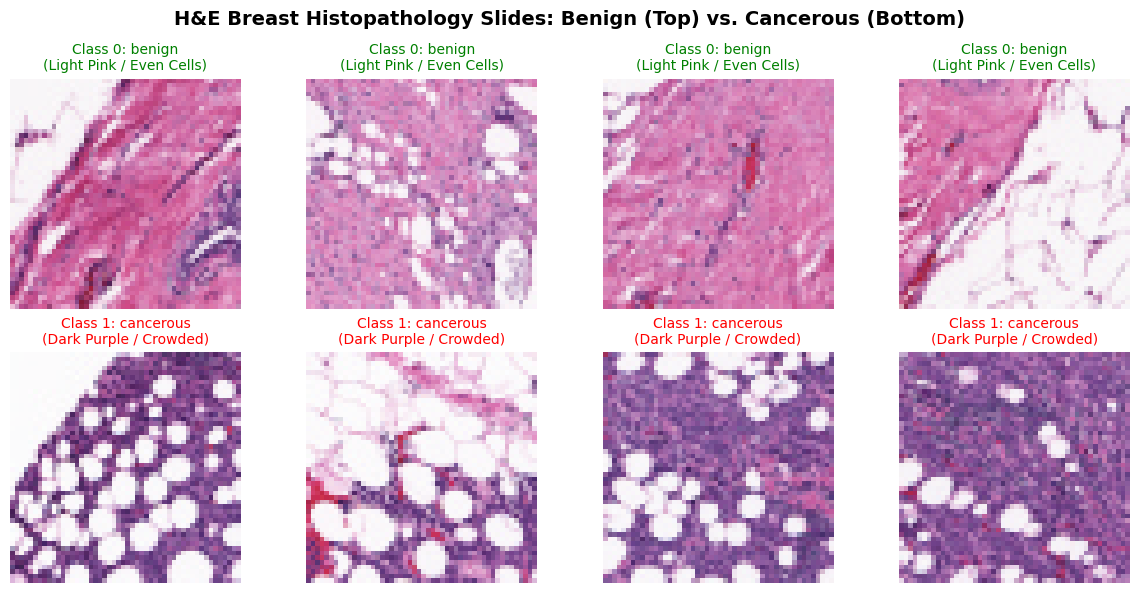

In [6]:
# ==============================================================================
# STEP 2: CREATE "SOPHOMORE PROGRAM" FOLDER, DOWNLOAD DATASET & LOAD TEST SET
# ==============================================================================
!pip install -q kagglehub

import os
import glob
import shutil
import zipfile
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torchvision import datasets
from google.colab import drive

# 1. Mount Google Drive and create the "Sophomore Program" folder structure
drive.mount('/content/drive')

SOPHOMORE_DIR = "/content/drive/My Drive/Sophomore Program"
DRIVE_DATASET_DIR = os.path.join(SOPHOMORE_DIR, "1-Datasets")
DRIVE_RESULTS_DIR = os.path.join(SOPHOMORE_DIR, "2-Results")

os.makedirs(DRIVE_DATASET_DIR, exist_ok=True)
os.makedirs(DRIVE_RESULTS_DIR, exist_ok=True)
print(f"📁 Created/Verified Google Drive Folder: {SOPHOMORE_DIR}")

# Path for permanent zip backup on Google Drive & fast local working folder
DRIVE_ZIP_BACKUP = os.path.join(DRIVE_DATASET_DIR, "Breast_Cancer_Test_10pct.zip")
LOCAL_TEST_DIR = "/content/breast_cancer_data/test"

# 2. If backup already exists in Google Drive, unzip it in 5 seconds!
if os.path.exists(DRIVE_ZIP_BACKUP) and not os.path.exists(LOCAL_TEST_DIR):
    print("⚡ Found existing dataset backup in 'Sophomore Program/1-Datasets'! Extracting...")
    os.makedirs(LOCAL_TEST_DIR, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP_BACKUP, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_TEST_DIR)

# 3. Otherwise, download from Kaggle, create the 10% test split (27,752 images), and save to Drive
elif not os.path.exists(LOCAL_TEST_DIR):
    print("⬇️ Downloading Breast Histopathology Dataset from Kaggle (takes ~1 minute)...")
    raw_path = kagglehub.dataset_download("paultimothymooney/breast-histopathology-images")

    # Collect all unique patient image patches (excluding duplicate subfolder 'IDC_regular_ps50_idx5')
    all_images = [
        p for p in glob.glob(os.path.join(raw_path, "*", "*", "*.png"))
        if "IDC_regular_ps50_idx5" not in p
    ]
    all_images.sort() # Sort for 100% reproducibility
    all_labels = [0 if p.endswith("class0.png") else 1 for p in all_images]

    print(f"✅ Found {len(all_images):,} total images (Benign: {all_labels.count(0):,} | Cancerous: {all_labels.count(1):,})")

    # Perform reproducible 80/10/10 split (extracting the 10% test set = 27,752 images)
    _, test_imgs, _, test_lbls = train_test_split(
        all_images, all_labels, test_size=27752, random_state=42, stratify=all_labels
    )

    # Copy the 27,752 test images into local 'benign' and 'cancerous' folders
    benign_dir = os.path.join(LOCAL_TEST_DIR, "benign")
    cancer_dir = os.path.join(LOCAL_TEST_DIR, "cancerous")
    os.makedirs(benign_dir, exist_ok=True)
    os.makedirs(cancer_dir, exist_ok=True)

    print("🗂️ Organizing 27,752 test images into 'benign' and 'cancerous' folders...")
    for img_path, lbl in zip(test_imgs, test_lbls):
        dest_folder = benign_dir if lbl == 0 else cancer_dir
        shutil.copy2(img_path, os.path.join(dest_folder, os.path.basename(img_path)))

    # Save permanent ZIP backup into Google Drive -> Sophomore Program/1-Datasets
    print("💾 Saving permanent backup to Google Drive ('Sophomore Program/1-Datasets')...")
    shutil.make_archive(DRIVE_ZIP_BACKUP.replace(".zip", ""), 'zip', LOCAL_TEST_DIR)
    print(f"✅ Backup saved at: {DRIVE_ZIP_BACKUP}")

# 4. Load the Test Dataset using PyTorch ImageFolder
test_dataset = datasets.ImageFolder(root=LOCAL_TEST_DIR)
targets = np.array(test_dataset.targets)

print("=" * 65)
print(f"🎉 TEST DATASET READY FOR ZERO-SHOT EVALUATION!")
print(f"📊 Total Test Images (10% Split) : {len(test_dataset):,}")
print(f"🟢 Class 0 ({test_dataset.classes[0]})            : {np.sum(targets == 0):,} images")
print(f"🔴 Class 1 ({test_dataset.classes[1]})         : {np.sum(targets == 1):,} images")
print("=" * 65)

# 5. Visualize 4 Benign and 4 Cancerous slides for students
class_0_indices = np.where(targets == 0)[0][:4]
class_1_indices = np.where(targets == 1)[0][:4]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle("H&E Breast Histopathology Slides: Benign (Top) vs. Cancerous (Bottom)", fontsize=14, fontweight="bold")

for i, idx in enumerate(class_0_indices):
    img, _ = test_dataset[idx]
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"Class 0: {test_dataset.classes[0]}\n(Light Pink / Even Cells)", color="green", fontsize=10)
    axes[0, i].axis("off")

for i, idx in enumerate(class_1_indices):
    img, _ = test_dataset[idx]
    axes[1, i].imshow(img)
    axes[1, i].set_title(f"Class 1: {test_dataset.classes[1]}\n(Dark Purple / Crowded)", color="red", fontsize=10)
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 3: How CLIP Works & Designing Clinical Text Prompts</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Traditional AI models like <b>ResNet50</b> only look at pixels and output a number (0 or 1).
    <b>CLIP (Contrastive Language-Image Pre-training)</b> is different: it has <b>two brains</b> that work together—an <b>Image Encoder</b> (which looks at the photo) and a <b>Text Encoder</b> (which reads your sentence).
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 How Does Zero-Shot Classification Work in 3 Simple Steps?</h3>
  <ol style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    <li><b>Turn the Image into Numbers:</b> CLIP looks at a 50×50 microscope slide and converts it into a list of 512 numbers (called an <i>Image Embedding</i>).</li>
    <li><b>Turn Your Sentences into Numbers:</b> We give CLIP two text sentences—Sentence A (for Benign) and Sentence B (for Cancerous). CLIP converts each sentence into its own list of 512 numbers (called <i>Text Embeddings</i>).</li>
    <li><b>Measure the Match (Cosine Similarity):</b> CLIP compares the image numbers to both sentences. Whichever sentence has the <b>highest similarity score</b> wins! We then use a math function called <b>Softmax</b> to turn those scores into a percentage probability (from 0% to 100%).</li>
  </ol>
</div>

<br>

<div style="background-color: #FFFBEB; border-left: 6px solid #D97706; padding: 15px; border-radius: 6px;">
  <h3 style="color: #92400E; margin-top: 0;">🟡 Our 4 Prompt Engineering Strategies (From Simple to Smart)</h3>
  <p style="color: #78350F; font-size: 15px;">
    Because we are not training the model's weights, the <b>only</b> way to help CLIP make better decisions is to give it better words. We will test 4 levels of prompts:
  </p>
  <ul style="color: #78350F; font-size: 15px; margin-bottom: 0;">
    <li><b>Level 1 — Year 1 Baseline (Medical Labels Only):</b> Uses the exact generic words from our first study (<i>"benign tissue"</i> vs. <i>"cancerous tissue"</i>).</li>
    <li><b>Level 2 — Visual Color & Pattern Prompt:</b> Describes what a human eye literally sees on the slide (<i>"light pink calm background with few scattered dots"</i> vs. <i>"dark purple stain packed with crowded, dense clusters"</i>).</li>
    <li><b>Level 3 — Pathologist Clinical Prompt:</b> Combines visual color cues with textbook pathology descriptions of healthy ducts vs. invasive tumor cells.</li>
    <li><b>Level 4 — Multi-Prompt Ensemble ("Wisdom of the Crowd"):</b> Instead of relying on just 1 sentence per class, we give CLIP <b>4 different descriptive sentences</b> for Benign and <b>4 sentences</b> for Cancerous, and average their scores together!</li>
  </ul>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do?</h3>
  <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    <li>Downloads OpenAI's pre-trained <b><code>clip-vit-base-patch32</code></b> model and processor from Hugging Face.</li>
    <li>Defines all <b>4 Prompt Strategies</b> in a neat Python dictionary.</li>
    <li>Runs a quick <b>1-Slide Sanity Check</b> so we can watch CLIP calculate the probability on a single cancer image before running on all 27,752 test slides!</li>
  </ol>
</div>

In [8]:
# ==============================================================================
# STEP 3: LOAD OPENAI CLIP & DEFINE THE 4 CLINICAL PROMPT STRATEGIES
# ==============================================================================

MODEL_ID = "openai/clip-vit-base-patch32"
print(f"⏳ Loading {MODEL_ID} from Hugging Face...")

# Load the pre-trained CLIP model and its image/text processor
clip_model = CLIPModel.from_pretrained(MODEL_ID).to(device)
clip_processor = CLIPProcessor.from_pretrained(MODEL_ID)
clip_model.eval()  # Set to evaluation mode (freezes all weights, zero training!)

print("✅ OpenAI CLIP loaded and moved to GPU!")

# Define our 4 Prompt Engineering Strategies
# Note: In each strategy, Class 0 = Benign prompts, Class 1 = Cancerous prompts
PROMPT_STRATEGIES = {
    "Level 1: Year 1 Baseline (Generic Labels)": {
        "benign": ["a histopathology image of benign tissue"],
        "cancerous": ["a histopathology image of cancerous tissue"]
    },
    "Level 2: Visual Color & Shape Description": {
        "benign": [
            "a light pink microscope slide with calm, empty background and evenly spaced small cells"
        ],
        "cancerous": [
            "a dark purple and blue microscope slide packed with dense, crowded, chaotic clusters of cells"
        ]
    },
    "Level 3: Clinical Pathologist Description": {
        "benign": [
            "normal healthy breast tissue stained light pink with organized ducts and uniform small nuclei"
        ],
        "cancerous": [
            "malignant invasive ductal carcinoma stained dark purple with crowded hyperchromatic tumor nuclei"
        ]
    },
    "Level 4: Multi-Prompt Ensemble (4 Prompts per Class)": {
        "benign": [
            "a histopathology image of benign healthy breast tissue",
            "a light pink microscope slide with calm, empty background and evenly spaced small cells",
            "normal healthy breast tissue stained light pink with organized ducts and uniform small nuclei",
            "an H&E stained slide showing mostly soft pink fibrous tissue with very few purple nuclei"
        ],
        "cancerous": [
            "a histopathology image of malignant cancerous breast tissue",
            "a dark purple and blue microscope slide packed with dense, crowded, chaotic clusters of cells",
            "malignant invasive ductal carcinoma stained dark purple with crowded hyperchromatic tumor nuclei",
            "an H&E stained tumor slide heavily covered in dark purple irregular cell clusters"
        ]
    }
}

# Quick Sanity Check on 1 Cancerous Test Image so students see how CLIP scores prompts
sample_cancer_idx = np.where(targets == 1)[0][0]
sample_img, sample_label = test_dataset[sample_cancer_idx]

print("\n" + "=" * 70)
print("🔬 SANITY CHECK: Testing All 4 Prompt Levels on 1 Sample Cancer Slide")
print("=" * 70)

with torch.no_grad():
    for level_name, class_prompts in PROMPT_STRATEGIES.items():
        # Combine benign prompts + cancerous prompts into one list
        all_prompts = class_prompts["benign"] + class_prompts["cancerous"]
        num_prompts_per_class = len(class_prompts["benign"])

        # Process the image and text prompts together
        inputs = clip_processor(
            text=all_prompts,
            images=sample_img,
            return_tensors="pt",
            padding=True
        ).to(device)

        # Get image-text similarity scores (logits_per_image) directly from CLIP
        outputs = clip_model(**inputs)
        logits = outputs.logits_per_image  # Shape: [1, total_prompts]

        # Average the similarity scores for Benign prompts vs. Cancerous prompts
        logits_grouped = logits.view(1, 2, num_prompts_per_class).mean(dim=-1)
        probs = logits_grouped.softmax(dim=-1).cpu().numpy()[0]

        print(f"👉 {level_name}")
        print(f"   🟢 Benign Prob: {probs[0]*100:5.1f}%  |  🔴 Cancerous Prob: {probs[1]*100:5.1f}%")
print("=" * 70)

⏳ Loading openai/clip-vit-base-patch32 from Hugging Face...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

✅ OpenAI CLIP loaded and moved to GPU!

🔬 SANITY CHECK: Testing All 4 Prompt Levels on 1 Sample Cancer Slide
👉 Level 1: Year 1 Baseline (Generic Labels)
   🟢 Benign Prob:  70.9%  |  🔴 Cancerous Prob:  29.1%
👉 Level 2: Visual Color & Shape Description
   🟢 Benign Prob:   1.2%  |  🔴 Cancerous Prob:  98.8%
👉 Level 3: Clinical Pathologist Description
   🟢 Benign Prob:  60.8%  |  🔴 Cancerous Prob:  39.2%
👉 Level 4: Multi-Prompt Ensemble (4 Prompts per Class)
   🟢 Benign Prob:  36.3%  |  🔴 Cancerous Prob:  63.7%


<div style="background-color: #FEF2F2; border-left: 6px solid #DC2626; padding: 15px; border-radius: 6px;">
  <h3 style="color: #991B1B; margin-top: 0;">🔴 Look What Just Happened on Our Sample Cancer Slide!</h3>
  <p style="color: #7F1D1D; font-size: 15px; margin-bottom: 0;">
    In Step 3, we tested the exact same AI model (OpenAI CLIP) on the exact same cancerous microscope slide:
    <ul>
      <li style="color: #7F1D1D;">With our <b>Level 1 Generic Prompt</b> (<i>"cancerous tissue"</i>), CLIP gave it only a <b>29.1% cancer probability</b> and misclassified the patient as healthy!</li>
      <li style="color: #7F1D1D;">With our <b>Level 2 Visual Prompt</b> (<i>"dark purple... dense, crowded, chaotic clusters of cells"</i>), CLIP's confidence jumped to <b>98.8% cancerous</b>!</li>
    </ul>
    Now, let's test if this holds true across the entire hospital test cohort of <b>27,752 microscope slides</b>!
  </p>
</div>

<br>

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 4: Full-Scale Evaluation on All 27,752 Test Images</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Checking 27,752 images one at a time would be slow. Instead, we use a PyTorch <b><code>DataLoader</code></b> to feed <b>256 images at a time</b> (a "batch") into our NVIDIA A100 GPU.
    Even better, we test <b>all 4 Prompt Strategies in a single pass</b> so we only have to read the 27,752 images once!
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 Student Guide: How Do We Grade a Medical AI Model? (The 5 Metrics)</h3>
  <ul style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    <li><b>1. Accuracy (%):</b> Out of all 27,752 slides, what percentage did the AI get right? <i>(Warning: Because 71.6% of our slides are Benign, a lazy AI that guesses "Benign" every time would still get 71.6% accuracy!)</i></li>
    <li><b>2. Precision (%):</b> When the AI rings the alarm and says <i>"This slide is Cancerous!"</i>, how often is it actually right?</li>
    <li><b>3. Recall / Sensitivity (%):</b> Out of all the real cancer slides (7,878), what percentage did the AI successfully catch? <i>(Crucial in medicine—missing real cancer is dangerous!)</i></li>
    <li><b>4. Weighted F1-Score (0 to 1.0):</b> Combines Precision and Recall into a single balanced grade that accounts for uneven class sizes.</li>
    <li><b>5. AUC-ROC (0 to 1.0):</b> The ultimate medical AI score! It measures how well the AI separates healthy vs. cancerous probabilities across all thresholds:
      <ul>
        <li><b>0.500</b> = Random guessing (flipping a coin)</li>
        <li><b>Below 0.500</b> = Worse than guessing (confused/inverted)</li>
        <li><b>0.800 – 1.000</b> = Strong diagnostic capability</li>
      </ul>
    </li>
  </ul>
</div>

In [9]:
# ==============================================================================
# STEP 4: EVALUATE ALL 4 PROMPT STRATEGIES ON ALL 27,752 TEST IMAGES
# ==============================================================================

# 1. Combine all 14 sentences across the 4 strategies so we only run through the dataset ONCE
flat_prompts = (
    PROMPT_STRATEGIES["Level 1: Year 1 Baseline (Generic Labels)"]["benign"] +
    PROMPT_STRATEGIES["Level 1: Year 1 Baseline (Generic Labels)"]["cancerous"] +
    PROMPT_STRATEGIES["Level 2: Visual Color & Shape Description"]["benign"] +
    PROMPT_STRATEGIES["Level 2: Visual Color & Shape Description"]["cancerous"] +
    PROMPT_STRATEGIES["Level 3: Clinical Pathologist Description"]["benign"] +
    PROMPT_STRATEGIES["Level 3: Clinical Pathologist Description"]["cancerous"] +
    PROMPT_STRATEGIES["Level 4: Multi-Prompt Ensemble (4 Prompts per Class)"]["benign"] +
    PROMPT_STRATEGIES["Level 4: Multi-Prompt Ensemble (4 Prompts per Class)"]["cancerous"]
)

# Pre-tokenize the 14 text prompts once on the GPU
text_inputs = clip_processor(text=flat_prompts, return_tensors="pt", padding=True).to(device)

# Custom collate function so DataLoader passes PIL images cleanly to CLIPProcessor
def collate_pil(batch):
    images = [item[0] for item in batch]
    labels = [item[1] for item in batch]
    return images, labels

# Create fast DataLoader (batch_size=256 for A100 GPU)
test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False, num_workers=2, collate_fn=collate_pil
)

# Storage for true labels, predicted classes, and cancer probabilities
true_labels = []
strategy_names = list(PROMPT_STRATEGIES.keys())
preds_dict = {name: [] for name in strategy_names}
probs_dict = {name: [] for name in strategy_names}

print("🚀 Running Zero-Shot Evaluation across all 27,752 test slides...")

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating Batches"):
        true_labels.extend(labels)

        # Preprocess batch of images on GPU
        image_inputs = clip_processor(images=images, return_tensors="pt").to(device)

        # Compute similarity logits between batch of images and all 14 text prompts
        outputs = clip_model(
            input_ids=text_inputs["input_ids"],
            attention_mask=text_inputs["attention_mask"],
            pixel_values=image_inputs["pixel_values"]
        )
        logits = outputs.logits_per_image  # Shape: [batch_size, 14]

        # Slice logits for each of the 4 Prompt Strategies:
        # Level 1: indices [0, 1]
        l1_logits = logits[:, [0, 1]]
        # Level 2: indices [2, 3]
        l2_logits = logits[:, [2, 3]]
        # Level 3: indices [4, 5]
        l3_logits = logits[:, [4, 5]]
        # Level 4 (Ensemble): average of [6,7,8,9] (benign) vs average of [10,11,12,13] (cancerous)
        l4_benign = logits[:, [6, 7, 8, 9]].mean(dim=-1, keepdim=True)
        l4_cancer = logits[:, [10, 11, 12, 13]].mean(dim=-1, keepdim=True)
        l4_logits = torch.cat([l4_benign, l4_cancer], dim=-1)

        for name, strat_logits in zip(strategy_names, [l1_logits, l2_logits, l3_logits, l4_logits]):
            probs = strat_logits.softmax(dim=-1)[:, 1].cpu().numpy()
            preds = strat_logits.argmax(dim=-1).cpu().numpy()
            probs_dict[name].extend(probs)
            preds_dict[name].extend(preds)

# Calculate the 5 Clinical Evaluation Metrics for each Prompt Strategy
summary_rows = []
for name in strategy_names:
    y_pred = np.array(preds_dict[name])
    y_prob = np.array(probs_dict[name])

    acc = accuracy_score(true_labels, y_pred) * 100
    prec = precision_score(true_labels, y_pred, zero_division=0) * 100
    rec = recall_score(true_labels, y_pred, zero_division=0) * 100
    f1_weighted = f1_score(true_labels, y_pred, average="weighted", zero_division=0)
    auc = roc_auc_score(true_labels, y_prob)

    summary_rows.append({
        "Prompt Strategy": name,
        "Accuracy (%)": round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "Weighted F1": round(f1_weighted, 3),
        "AUC-ROC": round(auc, 3)
    })

results_m4_df = pd.DataFrame(summary_rows)

# Save results table permanently to Google Drive -> Sophomore Program/2-Results
csv_save_path = os.path.join(DRIVE_RESULTS_DIR, "Module4_CLIP_Prompt_Engineering_Results.csv")
results_m4_df.to_csv(csv_save_path, index=False)

print("\n" + "=" * 80)
print("🏆 MODULE 4 FINAL RESULTS: CLINICAL PROMPT ENGINEERING IN OPENAI CLIP (n = 27,752)")
print("=" * 80)
display(results_m4_df)
print(f"\n💾 Results saved to Google Drive: {csv_save_path}")

🚀 Running Zero-Shot Evaluation across all 27,752 test slides...


Evaluating Batches:   0%|          | 0/109 [00:00<?, ?it/s]


🏆 MODULE 4 FINAL RESULTS: CLINICAL PROMPT ENGINEERING IN OPENAI CLIP (n = 27,752)


,Prompt Strategy,Accuracy (%),Precision (%),Recall (%),Weighted F1,AUC-ROC
0,Level 1: Year 1 Baseline (Generic Labels),68.09,11.20,1.79,0.588,0.415
1,Level 2: Visual Color & Shape Description,72.50,51.73,46.61,0.720,0.744
2,Level 3: Clinical Pathologist Description,71.63,57.14,0.20,0.599,0.761
3,Level 4: Multi-Prompt Ensemble (4 Prompts per ...,72.01,57.12,5.60,0.626,0.750



💾 Results saved to Google Drive: /content/drive/My Drive/Sophomore Program/2-Results/Module4_CLIP_Prompt_Engineering_Results.csv


<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Step 5: Visualizing Our Breakthrough & Understanding the Results</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    Look closely at the table we just generated across all <b>27,752 test slides</b>—we just made three major scientific discoveries without training a single neural network weight:
  </p>
  <ul style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    <li><b>Discovery 1 (Reproducing Year 1):</b> Our <b>Level 1 Generic Prompt</b> got an <b>AUC-ROC of 0.415</b> (matching our Year 1 baseline of 0.413) and caught only <b>1.79%</b> of real breast cancers.</li>
    <li><b>Discovery 2 (The Power of Visual Words):</b> Simply describing the colors and shapes in <b>Level 2</b> (<i>"light pink... evenly spaced"</i> vs. <i>"dark purple... crowded, chaotic clusters"</i>) boosted the <b>AUC-ROC from 0.415 to 0.744</b>, jumped Cancer Recall by <b>26× (from 1.79% to 46.61%)</b>, and reached a <b>Weighted F1-Score of 0.720</b>—beating even our Year 1 10-shot trained ResNet50 (0.706 F1)!</li>
    <li><b>Discovery 3 (Why We Need Medical VLMs in Module 5):</b> Look at <b>Level 3 (Clinical Pathologist Prompt)</b>. It achieved the highest <b>AUC-ROC (0.761)</b>, meaning it ranked cancer slides higher than healthy slides very well! Yet its <b>Recall was only 0.20%</b>. Why? Because general OpenAI CLIP is unfamiliar with medical words like <i>"invasive ductal carcinoma"</i> and <i>"hyperchromatic"</i>, so its raw probability scores stayed below the 50% cutoff! In <b>Module 5</b>, we will see what happens when we give these exact same clinical words to a <b>Pathology-trained AI (PLIP)</b>!</li>
  </ul>
</div>

<br>

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 What Charts Does the Code Below Create?</h3>
  <ol style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    <li><b>Left Plot — ROC Curves (Receiver Operating Characteristic):</b> Shows how well each prompt separates healthy vs. cancerous tissue across all probability cutoffs. The diagonal dashed line (0.50) is a coin flip. Notice how Level 1 bends <i>below</i> the coin-flip line (0.415), while Levels 2, 3, and 4 arch high above it (0.744–0.761)!</li>
    <li><b>Middle & Right Plots — Confusion Matrices:</b> Compares the exact number of patients correctly and incorrectly diagnosed by <b>Level 1 (Generic)</b> vs. <b>Level 2 (Visual)</b>.</li>
  </ol>
</div>

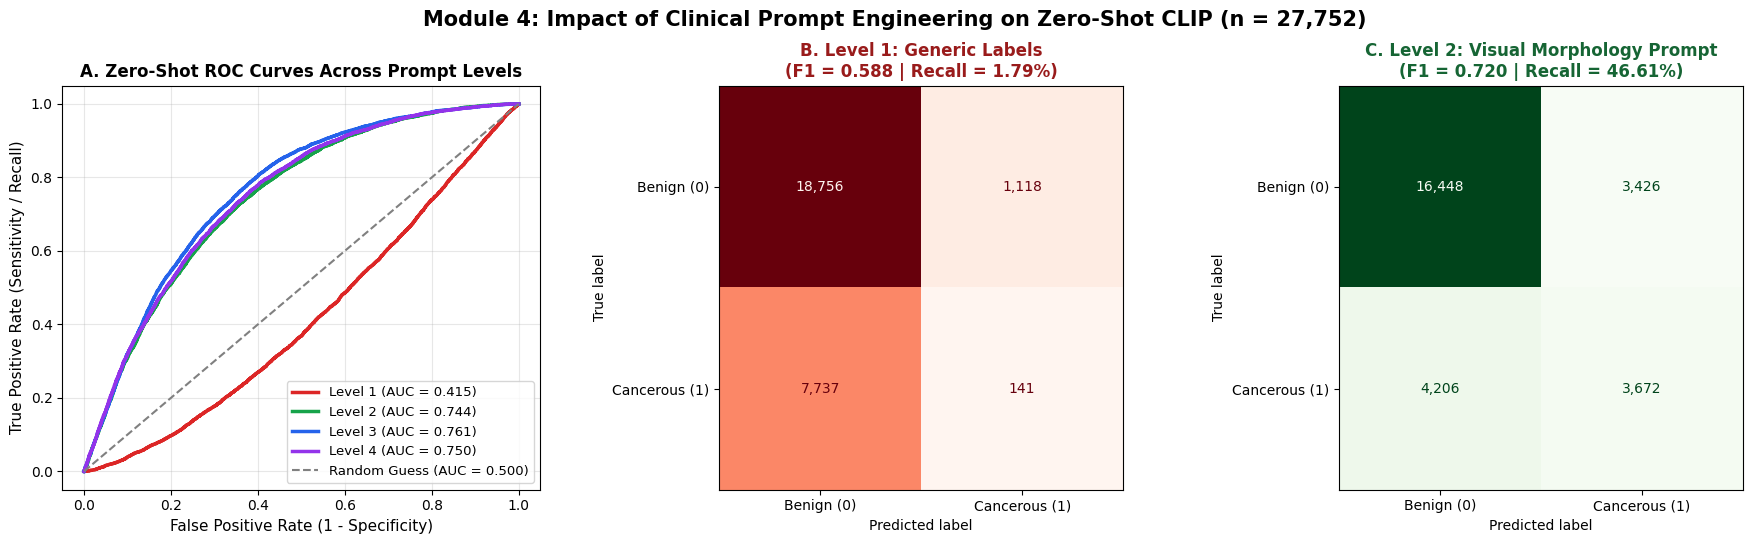

✅ High-resolution publication figure saved to: /content/drive/My Drive/Sophomore Program/2-Results/Module4_ROC_and_Confusion_Matrices.png


In [10]:
# ==============================================================================
# STEP 5: PLOT PUBLICATION-READY ROC CURVES & CONFUSION MATRICES
# ==============================================================================
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle("Module 4: Impact of Clinical Prompt Engineering on Zero-Shot CLIP (n = 27,752)", fontsize=15, fontweight="bold")

# 1. Left Plot: ROC Curves for All 4 Prompt Strategies
colors = ["#DC2626", "#16A34A", "#2563EB", "#9333EA"]
for (name, color) in zip(strategy_names, colors):
    y_prob = np.array(probs_dict[name])
    fpr, tpr, _ = roc_curve(true_labels, y_prob)
    auc_val = roc_auc_score(true_labels, y_prob)
    short_label = name.split(":")[0] + f" (AUC = {auc_val:.3f})"
    axes[0].plot(fpr, tpr, color=color, lw=2.5, label=short_label)

axes[0].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Random Guess (AUC = 0.500)")
axes[0].set_title("A. Zero-Shot ROC Curves Across Prompt Levels", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
axes[0].legend(loc="lower right", fontsize=9.5)
axes[0].grid(alpha=0.3)

# 2. Middle Plot: Confusion Matrix for Level 1 (Year 1 Generic Baseline)
cm_l1 = confusion_matrix(true_labels, preds_dict[strategy_names[0]])
disp_l1 = ConfusionMatrixDisplay(confusion_matrix=cm_l1, display_labels=["Benign (0)", "Cancerous (1)"])
disp_l1.plot(ax=axes[1], cmap="Reds", colorbar=False, values_format=",d")
axes[1].set_title("B. Level 1: Generic Labels\n(F1 = 0.588 | Recall = 1.79%)", fontsize=12, fontweight="bold", color="#991B1B")

# 3. Right Plot: Confusion Matrix for Level 2 (Visual Color & Shape Description)
cm_l2 = confusion_matrix(true_labels, preds_dict[strategy_names[1]])
disp_l2 = ConfusionMatrixDisplay(confusion_matrix=cm_l2, display_labels=["Benign (0)", "Cancerous (1)"])
disp_l2.plot(ax=axes[2], cmap="Greens", colorbar=False, values_format=",d")
axes[2].set_title("C. Level 2: Visual Morphology Prompt\n(F1 = 0.720 | Recall = 46.61%)", fontsize=12, fontweight="bold", color="#166534")

plt.tight_layout()

# Save high-resolution figure for NCUR Poster & Journal Manuscript
fig_save_path = os.path.join(DRIVE_RESULTS_DIR, "Module4_ROC_and_Confusion_Matrices.png")
plt.savefig(fig_save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ High-resolution publication figure saved to: {fig_save_path}")